# Multiple-period Brinson attribution and linking

This tutorial uses the same local synthetic Dow 30 portfolio over 12 months. Every attribution chart or table that uses linked effects names the selected linking method. Returns and effects are decimal values.

## 1. Load the local data

The CSV inputs are in `data/dow30_brinson/`. Start Jupyter from the repository root or either language tutorial folder.

In [1]:
from pathlib import Path
import sys
import polars as pl
import matplotlib.pyplot as plt

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "brinsons").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Launch Jupyter from the project root or tutorials/.")
sys.path.insert(0, str(ROOT / "src"))
from brinsons import (
    ColumnNames, bhb, fachler, calculate_multiple_period,
    link_carino, link_grap, link_frongello, link_menchero, link_geometric,
    print_multiple_period_category_weights, print_multiple_period_category_returns,
    print_multiple_period_category_attribution, print_multiple_period_total_attribution,
    print_multiple_period_attribution_summary, chart_multiple_period_category_returns,
    chart_multiple_period_category_weights, chart_multiple_period_category_attribution,
    chart_multiple_period_excess_return_waterfall,
)

asset = pl.read_csv(ROOT / "data" / "dow30_brinson" / "asset_table.csv")
periods = pl.read_csv(ROOT / "data" / "dow30_brinson" / "periods.csv")
print(f"{asset['Name'].n_unique()} stocks, {periods.height} monthly periods")
display(asset.head(6))

30 stocks, 12 monthly periods


Period,Name,Return,Category,PortfolioWeight,BenchmarkWeight
i64,str,f64,str,f64,f64
1,"""AAPL""",0.061815,"""Technology""",0.032875,0.033333
1,"""AMGN""",0.057512,"""Healthcare""",0.030001,0.033333
1,"""AMZN""",0.112265,"""Consumer Cyclical""",0.031268,0.033333
1,"""AXP""",0.088764,"""Financial Services""",0.035456,0.033333
1,"""BA""",-0.068619,"""Industrials""",0.034092,0.033333
1,"""CAT""",0.213284,"""Industrials""",0.036527,0.033333


## 2. Build sector returns

Aggregate asset contributions by month and sector. The original input column names are retained through `ColumnNames`.

In [2]:
sector = asset.group_by(["Period", "Category"]).agg(
    pl.col("PortfolioWeight", "BenchmarkWeight").sum(),
    (pl.col("PortfolioWeight") * pl.col("Return")).sum().alias("PortfolioContribution"),
    (pl.col("BenchmarkWeight") * pl.col("Return")).sum().alias("BenchmarkContribution"),
).with_columns(
    (pl.col("PortfolioContribution") / pl.col("PortfolioWeight")).alias("PortfolioReturn"),
    (pl.col("BenchmarkContribution") / pl.col("BenchmarkWeight")).alias("BenchmarkReturn"),
).sort(["Period", "Category"])
column_names = ColumnNames(period="Period", segment="Category",
    portfolio_weight="PortfolioWeight", benchmark_weight="BenchmarkWeight",
    portfolio_return="PortfolioReturn", benchmark_return="BenchmarkReturn")
display(sector.head())

Period,Category,PortfolioWeight,BenchmarkWeight,PortfolioContribution,BenchmarkContribution,PortfolioReturn,BenchmarkReturn
i64,str,f64,f64,f64,f64,f64,f64
1,"""Basic Materials""",0.022769,0.033333,-0.000087,-0.000127,-0.003812,-0.003812
1,"""Communication Services""",0.069037,0.066667,0.005063,0.004676,0.073338,0.070133
1,"""Consumer Cyclical""",0.119859,0.133333,-0.001293,-0.00142,-0.010789,-0.010649
1,"""Consumer Defensive""",0.087666,0.1,0.000361,0.000205,0.004122,0.002052
1,"""Energy""",0.023962,0.033333,0.000375,0.000522,0.015648,0.015648


## 3. Calculate the period effects and link them

`calculate_multiple_period` returns separate per-period and linked results. Here the Brinson method is BF and the linking method is **Menchero**. Arithmetic linking reconciles to $\prod_t(1+R_{P,t})-\prod_t(1+R_{B,t})$.

In [3]:
multiple = calculate_multiple_period(sector, attribution=fachler, linking=link_menchero, columns=column_names)
print('Multiple-period linking method: Menchero')
result = multiple.periods  # reporting tools link the period results with Menchero
display(multiple.periods.summary.head())
display(multiple.linked.summary)

Multiple-period linking method: Menchero


Period,allocation,selection,interaction,portfolio_return,benchmark_return,excess_return
i64,f64,f64,f64,f64,f64,f64
1,0.002055,0.000609,-0.000096,0.031872,0.029305,0.002568
2,-0.000366,-0.000947,-0.00026,0.013316,0.01489,-0.001574
3,0.002129,0.001093,-0.00009,0.011123,0.007992,0.003132
4,-0.007307,-0.00075,-0.000017,0.014124,0.022198,-0.008074
5,-0.005286,-0.001253,-0.000233,0.002911,0.009683,-0.006772


allocation,selection,interaction,portfolio_return,benchmark_return,excess_return
f64,f64,f64,f64,f64,f64
0.006768,-0.006223,-0.00056,0.143557,0.143573,-0.000016


## 4. Compare all linking methods on the same data

Cariño, GRAP, Frongello and Menchero target arithmetic compounded excess. Geometric targets relative compounded return and includes a multiplicative cross term. BHB/BF and two-/three-effect choices are included.

In [4]:
linkers = [("Cariño", link_carino), ("GRAP", link_grap),
           ("Frongello", link_frongello), ("Menchero", link_menchero),
           ("Geometric", link_geometric)]
arithmetic_rows = []
geometric_rows = []
for brinson_name, brinson_fn in [("BHB", bhb), ("BF", fachler)]:
    for effect_count in (2, 3):
        for linker_name, linker_fn in linkers:
            run = calculate_multiple_period(sector, attribution=brinson_fn,
                linking=linker_fn, effects=effect_count, columns=column_names)
            names = run.linked.columns
            totals = run.linked.summary.row(0, named=True)
            allocation = totals[names.summary_allocation]
            selection = totals[names.summary_selection]
            interaction = totals[names.summary_interaction]
            active = totals[names.summary_excess_return]
            common = {"Brinson": brinson_name, "Effects": effect_count, "Linking": linker_name,
                      "Portfolio (bp)": 10_000 * totals[names.summary_portfolio_return],
                      "Benchmark (bp)": 10_000 * totals[names.summary_benchmark_return]}
            if linker_name == "Geometric":
                geometric_rows.append({**common, "Relative active (bp)": 10_000 * active,
                    "Allocation (bp)": 10_000 * allocation,
                    "Selection incl. interaction (bp)": 10_000 * selection,
                    "Cross term (bp)": 10_000 * allocation * selection,
                    "Residual (bp)": 10_000 * ((1 + allocation) * (1 + selection) - 1 - active)})
            else:
                arithmetic_rows.append({**common, "Active (bp)": 10_000 * active,
                    "Allocation (bp)": 10_000 * allocation,
                    "Selection (bp)": 10_000 * selection,
                    "Interaction (bp)": 10_000 * interaction,
                    "Residual (bp)": 10_000 * (allocation + selection + interaction - active)})

arithmetic_comparison = pl.DataFrame(arithmetic_rows)
geometric_comparison = pl.DataFrame(geometric_rows)
assert arithmetic_comparison["Residual (bp)"].abs().max() < 1e-6
assert geometric_comparison["Residual (bp)"].abs().max() < 1e-6
with pl.Config(tbl_rows=100, tbl_cols=12, tbl_width_chars=180, fmt_str_lengths=32):
    display(arithmetic_comparison)
    display(geometric_comparison)


Brinson,Effects,Linking,Portfolio (bp),Benchmark (bp),Active (bp),Allocation (bp),Selection (bp),Interaction (bp),Residual (bp)
str,i64,str,f64,f64,f64,f64,f64,f64,f64
"""BHB""",2,"""Cariño""",1435.574906,1435.732681,-0.157775,65.229373,-65.387148,0.0,4.0072e-12
"""BHB""",2,"""GRAP""",1435.574906,1435.732681,-0.157775,64.912374,-65.070149,0.0,3.9378e-12
"""BHB""",2,"""Frongello""",1435.574906,1435.732681,-0.157775,64.912374,-65.070149,0.0,3.9378e-12
"""BHB""",2,"""Menchero""",1435.574906,1435.732681,-0.157775,67.677732,-67.835508,0.0,-1.7347e-14
"""BHB""",3,"""Cariño""",1435.574906,1435.732681,-0.157775,65.229373,-59.735387,-5.651761,3.9942e-12
"""BHB""",3,"""GRAP""",1435.574906,1435.732681,-0.157775,64.912374,-59.412622,-5.657527,3.8988e-12
"""BHB""",3,"""Frongello""",1435.574906,1435.732681,-0.157775,64.912374,-59.412622,-5.657527,3.8988e-12
"""BHB""",3,"""Menchero""",1435.574906,1435.732681,-0.157775,67.677732,-62.233447,-5.602061,-3.9031e-14
"""BF""",2,"""Cariño""",1435.574906,1435.732681,-0.157775,65.229373,-65.387148,0.0,3.9031e-12


Brinson,Effects,Linking,Portfolio (bp),Benchmark (bp),Relative active (bp),Allocation (bp),Selection incl. interaction (bp),Cross term (bp),Residual (bp)
str,i64,str,f64,f64,f64,f64,f64,f64,f64
"""BHB""",2,"""Geometric""",1435.574906,1435.732681,-0.137967,57.220682,-57.032306,-0.326343,4.4409e-12
"""BHB""",3,"""Geometric""",1435.574906,1435.732681,-0.137967,57.220682,-57.032306,-0.326343,4.4409e-12
"""BF""",2,"""Geometric""",1435.574906,1435.732681,-0.137967,57.220682,-57.032306,-0.326343,4.4409e-12
"""BF""",3,"""Geometric""",1435.574906,1435.732681,-0.137967,57.220682,-57.032306,-0.326343,4.4409e-12


### Total attribution for each named linker

In [5]:
for linker_name, linker_fn in linkers:
    print_multiple_period_total_attribution(result, linking=linker_fn)


### Total Attribution — All periods | Linking: Cariño

All-period effects use Cariño linking and reconcile to the difference of compounded returns.

| Allocation | Selection | Interaction | Active return |
| --- | --- | --- | --- |
| 0.6523% | -0.5974% | -0.0565% | -0.0016% |

### Total Attribution — All periods | Linking: GRAP

All-period effects use GRAP linking and reconcile to the difference of compounded returns.

| Allocation | Selection | Interaction | Active return |
| --- | --- | --- | --- |
| 0.6491% | -0.5941% | -0.0566% | -0.0016% |

### Total Attribution — All periods | Linking: Frongello

All-period effects use Frongello linking and reconcile to the difference of compounded returns.

| Allocation | Selection | Interaction | Active return |
| --- | --- | --- | --- |
| 0.6491% | -0.5941% | -0.0566% | -0.0016% |

### Total Attribution — All periods | Linking: Menchero

All-period effects use Menchero linking and reconcile to the difference of compounded returns.

| Allocation | Selection | Interaction | Active return |
| --- | --- | --- | --- |
| 0.6768% | -0.6223% | -0.0560% | -0.0016% |

### Total Attribution — All periods | Linking: Geometric

Geometric effects reconcile multiplicatively: (1 + allocation)(1 + selection) - 1 = relative active return.

| Allocation | Selection incl. interaction | Cross term | Relative active return |
| --- | --- | --- | --- |
| 0.5722% | -0.5703% | -0.0033% | -0.0014% |

### Arithmetic linking comparison chart

Each row identifies its linker. GRAP and Frongello share the same factors in this implementation.

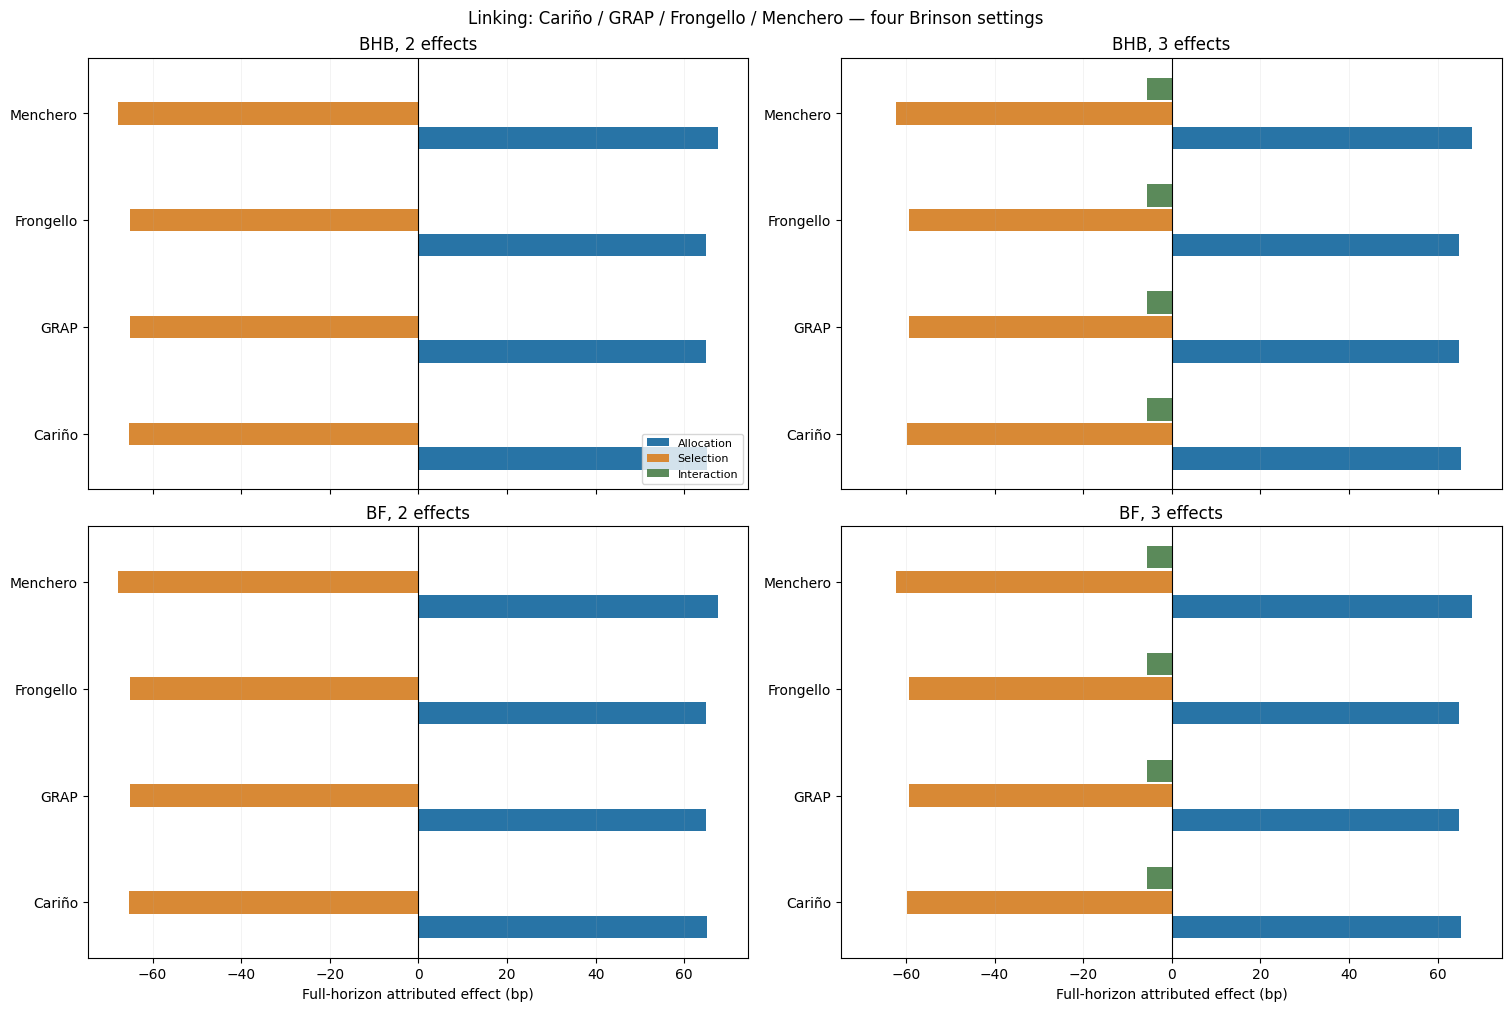

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharex=True, layout="constrained")
for ax, (brinson_name, effect_count) in zip(axes.flat,
                                            [("BHB", 2), ("BHB", 3), ("BF", 2), ("BF", 3)]):
    rows = arithmetic_comparison.filter(
        (pl.col("Brinson") == brinson_name) & (pl.col("Effects") == effect_count))
    positions = list(range(rows.height))
    for offset, field, color in [(-0.23, "Allocation (bp)", "#2874a6"),
                                 (0.00, "Selection (bp)", "#d88935"),
                                 (0.23, "Interaction (bp)", "#5b8a5a")]:
        ax.barh([p + offset for p in positions], rows[field].to_list(),
                height=0.21, label=field.replace(" (bp)", ""), color=color)
    ax.set_yticks(positions, rows["Linking"].to_list())
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"{brinson_name}, {effect_count} effects")
    ax.grid(axis="x", alpha=0.2)
axes[0, 0].legend(loc="lower right", fontsize=8)
for ax in axes[1]:
    ax.set_xlabel("Full-horizon attributed effect (bp)")
fig.suptitle("Linking: Cariño / GRAP / Frongello / Menchero — four Brinson settings")
plt.show()


### Geometric linking comparison chart

Allocation plus selection alone does not equal the relative total; include their cross term.

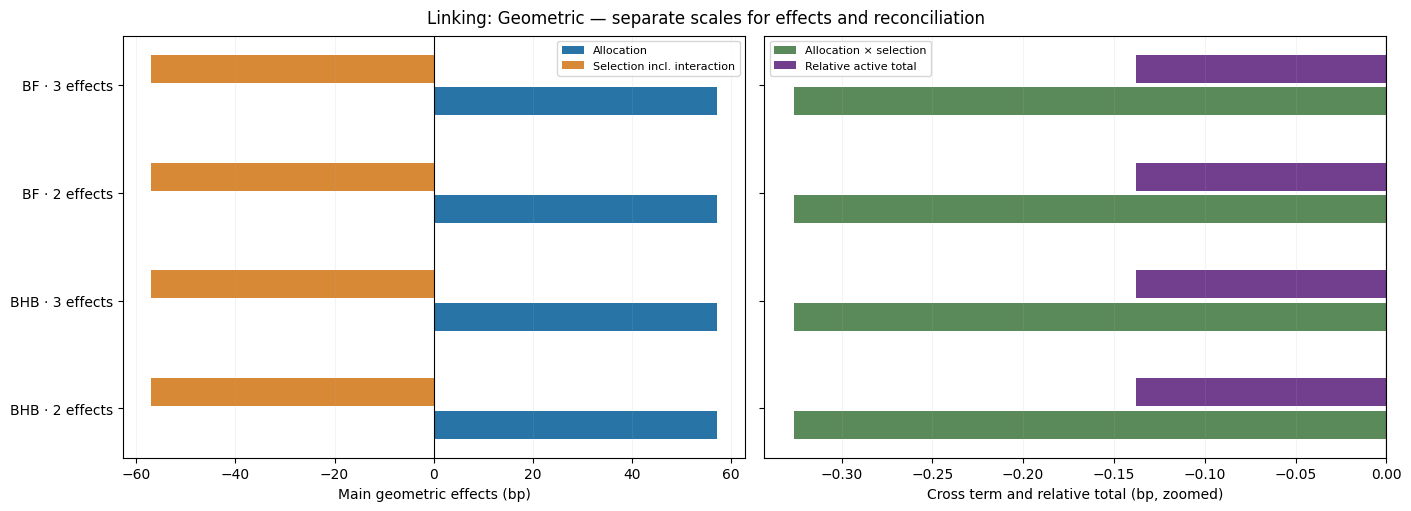

In [7]:
geometric_labels = [f"{row['Brinson']} · {row['Effects']} effects"
                    for row in geometric_comparison.iter_rows(named=True)]
positions = list(range(geometric_comparison.height))
fig, (ax_large, ax_small) = plt.subplots(1, 2, figsize=(14, 5), sharey=True, layout="constrained")
for offset, field, color, label in [
    (-0.15, "Allocation (bp)", "#2874a6", "Allocation"),
    (0.15, "Selection incl. interaction (bp)", "#d88935", "Selection incl. interaction")]:
    ax_large.barh([p + offset for p in positions], geometric_comparison[field].to_list(),
                  height=0.26, label=label, color=color)
for offset, field, color, label in [
    (-0.15, "Cross term (bp)", "#5b8a5a", "Allocation × selection"),
    (0.15, "Relative active (bp)", "#713f8e", "Relative active total")]:
    ax_small.barh([p + offset for p in positions], geometric_comparison[field].to_list(),
                  height=0.26, label=label, color=color)
ax_large.set_yticks(positions, geometric_labels)
for axis in (ax_large, ax_small):
    axis.axvline(0, color="black", linewidth=0.8)
    axis.grid(axis="x", alpha=0.2)
    axis.legend(fontsize=8)
ax_large.set_xlabel("Main geometric effects (bp)")
ax_small.set_xlabel("Cross term and relative total (bp, zoomed)")
fig.suptitle("Linking: Geometric — separate scales for effects and reconciliation")
plt.show()


## 5. Category weights (linking: none)

In [8]:
print_multiple_period_category_weights(result);

### Category Weights — All periods | Linking: none

Active weight = portfolio weight − benchmark weight. Across all periods, weights are simple period averages.

| Category | Portfolio | Benchmark | Active |
| --- | --- | --- | --- |
| Basic Materials | 2.5830% | 3.3333% | -0.7503% |
| Communication Services | 6.5103% | 6.6667% | -0.1564% |
| Consumer Cyclical | 12.3570% | 13.3333% | -0.9763% |
| Consumer Defensive | 8.4258% | 10.0000% | -1.5742% |
| Energy | 2.3921% | 3.3333% | -0.9413% |
| Financial Services | 17.2935% | 16.6667% | 0.6268% |
| Healthcare | 13.7498% | 13.3333% | 0.4165% |
| Industrials | 12.4008% | 13.3333% | -0.9325% |
| Technology | 24.2877% | 20.0000% | 4.2877% |

## 6. Category returns (linking: none)

In [9]:
print_multiple_period_category_returns(result);

### Category Returns — All periods | Linking: none

Across all periods, category returns compound period category returns; within-category weights reset each period.

| Category | Portfolio | Benchmark |
| --- | --- | --- |
| Basic Materials | -5.7539% | -5.7539% |
| Communication Services | 17.0686% | 17.2176% |
| Consumer Cyclical | -21.5466% | -21.6581% |
| Consumer Defensive | 11.3609% | 10.3414% |
| Energy | 36.6842% | 36.6842% |
| Financial Services | 10.3518% | 10.5832% |
| Healthcare | 45.5508% | 48.6286% |
| Industrials | 16.5641% | 17.8434% |
| Technology | 16.1861% | 17.1908% |

## 7. Category attribution (linking: Menchero)

In [10]:
print_multiple_period_category_attribution(result, linking=link_menchero);

### Category Attribution — All periods | Linking: Menchero

Allocation + selection + interaction = active contribution. All-period effects use Menchero linking.

| Category | Allocation | Selection | Interaction | Active |
| --- | --- | --- | --- | --- |
| Basic Materials | 0.2081% | -0.0000% | 0.0000% | 0.2081% |
| Communication Services | 0.0242% | -0.0028% | -0.0014% | 0.0200% |
| Consumer Cyclical | 0.4060% | 0.0085% | -0.0083% | 0.4061% |
| Consumer Defensive | -0.1202% | 0.1105% | -0.0114% | -0.0211% |
| Energy | 0.0636% | -0.0000% | 0.0000% | 0.0636% |
| Financial Services | -0.0332% | -0.0404% | -0.0062% | -0.0797% |
| Healthcare | 0.1672% | -0.3357% | -0.0013% | -0.1699% |
| Industrials | -0.0794% | -0.1642% | 0.0014% | -0.2422% |
| Technology | 0.0406% | -0.1983% | -0.0288% | -0.1865% |

## 8. Total attribution (linking: Menchero)

In [11]:
print_multiple_period_total_attribution(result, linking=link_menchero);

### Total Attribution — All periods | Linking: Menchero

All-period effects use Menchero linking and reconcile to the difference of compounded returns.

| Allocation | Selection | Interaction | Active return |
| --- | --- | --- | --- |
| 0.6768% | -0.6223% | -0.0560% | -0.0016% |

## 9. Performance-attribution summary (linking: Menchero)

In [12]:
print_multiple_period_attribution_summary(result, linking=link_menchero);

### Summary for Performance Attribution — All periods | Linking: Menchero

All-period effects use Menchero linking.

| Measure | Value |
| --- | --- |
| Categories | 9 |
| Periods | 12 |
| Portfolio return | 14.3557% |
| Benchmark return | 14.3573% |
| Active return | -0.0016% |
| Allocation | 0.6768% |
| Selection | -0.6223% |
| Interaction | -0.0560% |

## 10. Horizontal bars: category returns (linking: none)

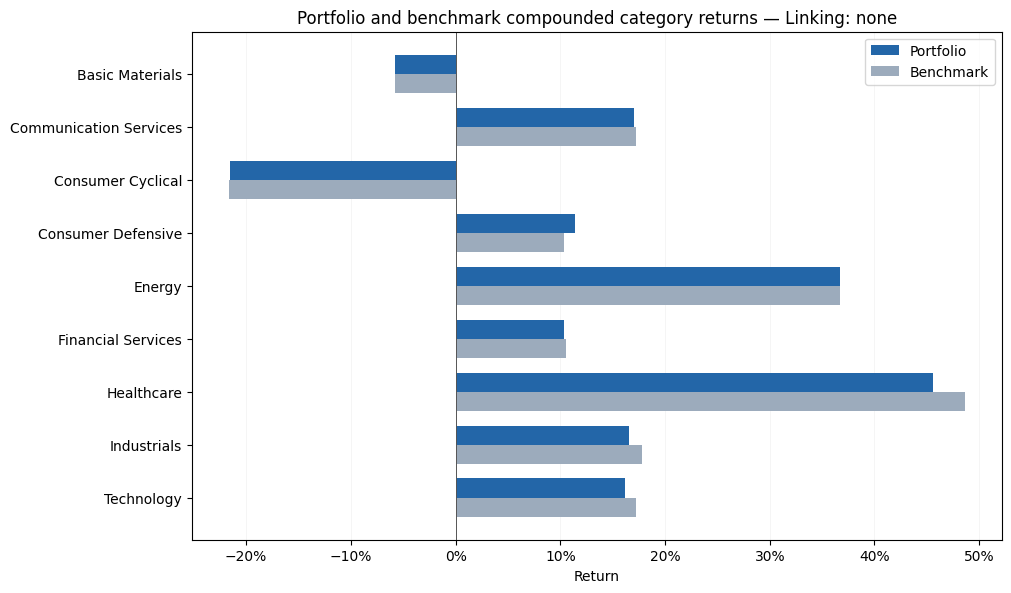

In [13]:
fig, ax = chart_multiple_period_category_returns(result)
plt.show()

## 11. Horizontal bars: category weights (linking: none)

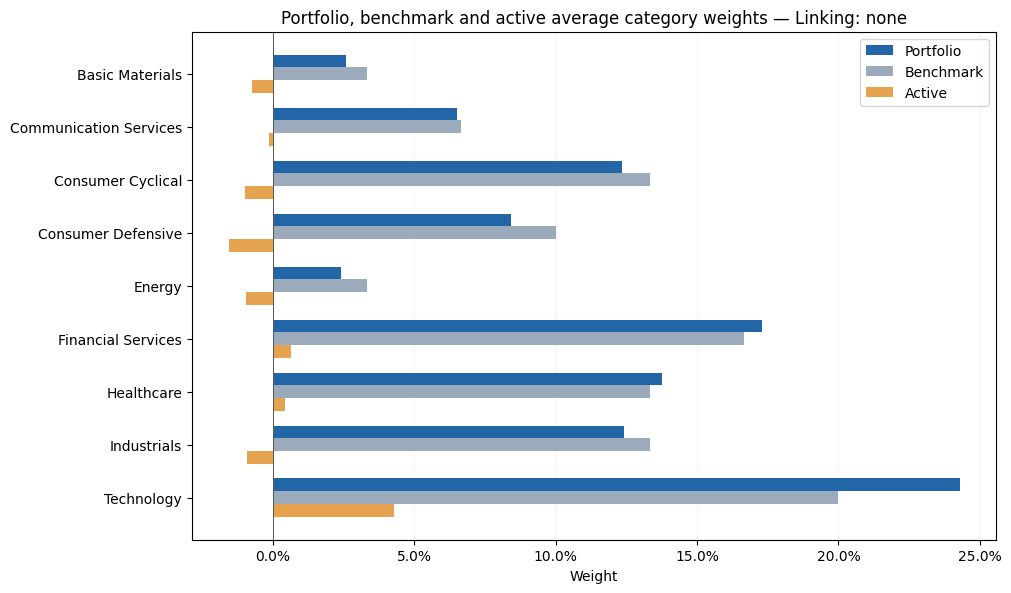

In [14]:
fig, ax = chart_multiple_period_category_weights(result)
plt.show()

## 12. Horizontal bars: category attribution (linking: Menchero)

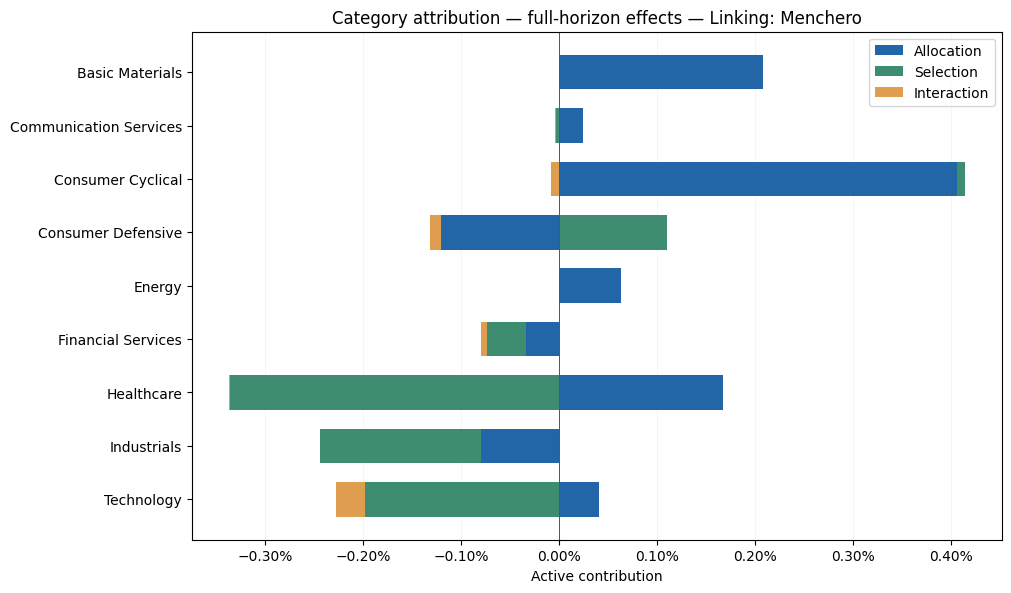

In [15]:
fig, ax = chart_multiple_period_category_attribution(result, linking=link_menchero)
plt.show()

## 13. Category waterfalls for four arithmetic linkers

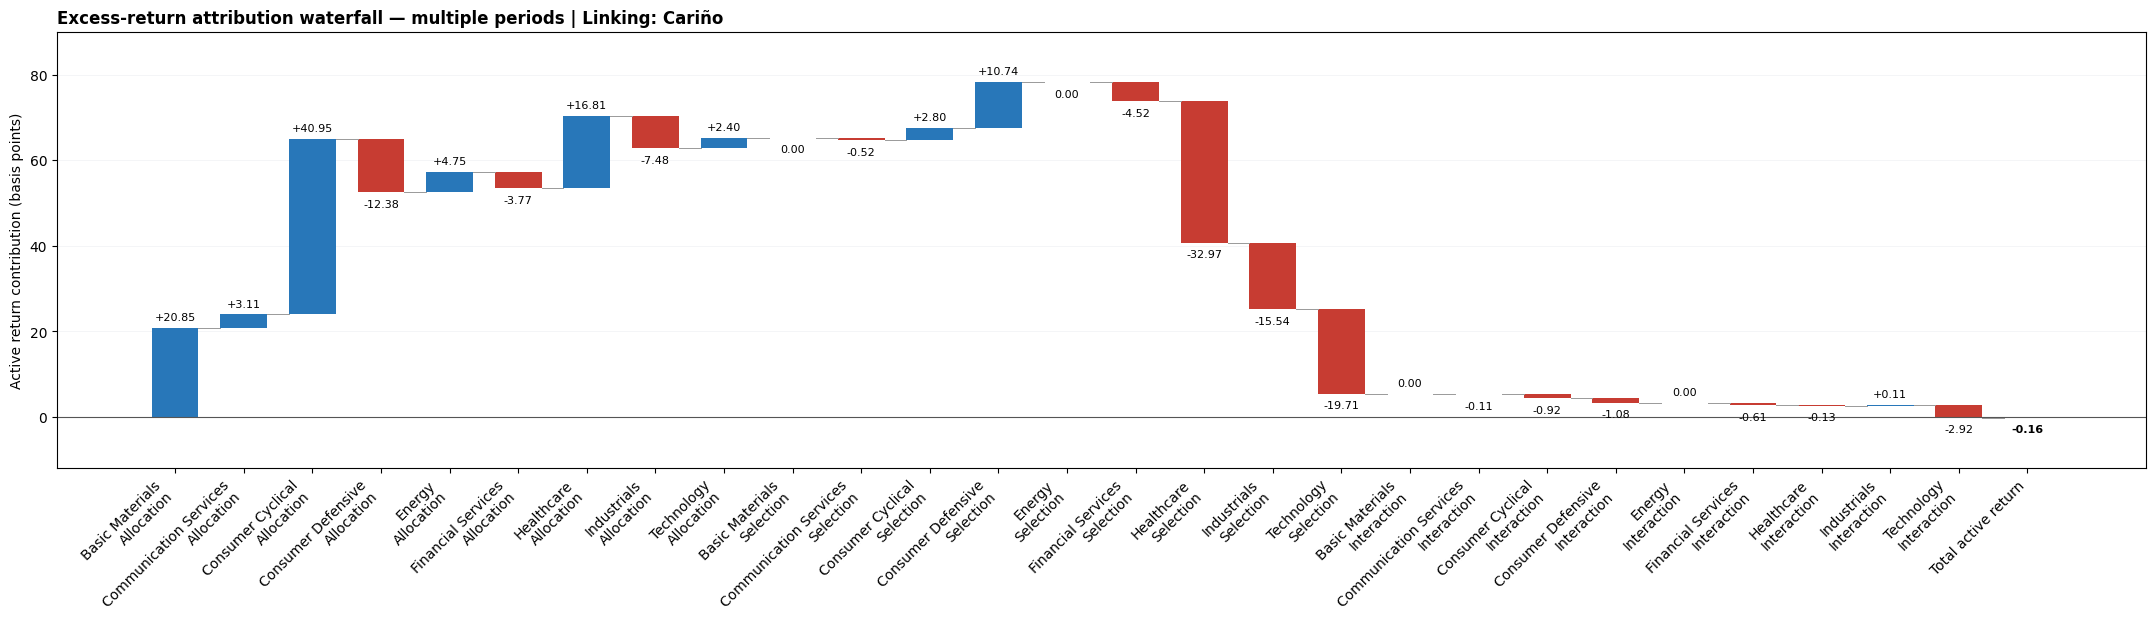

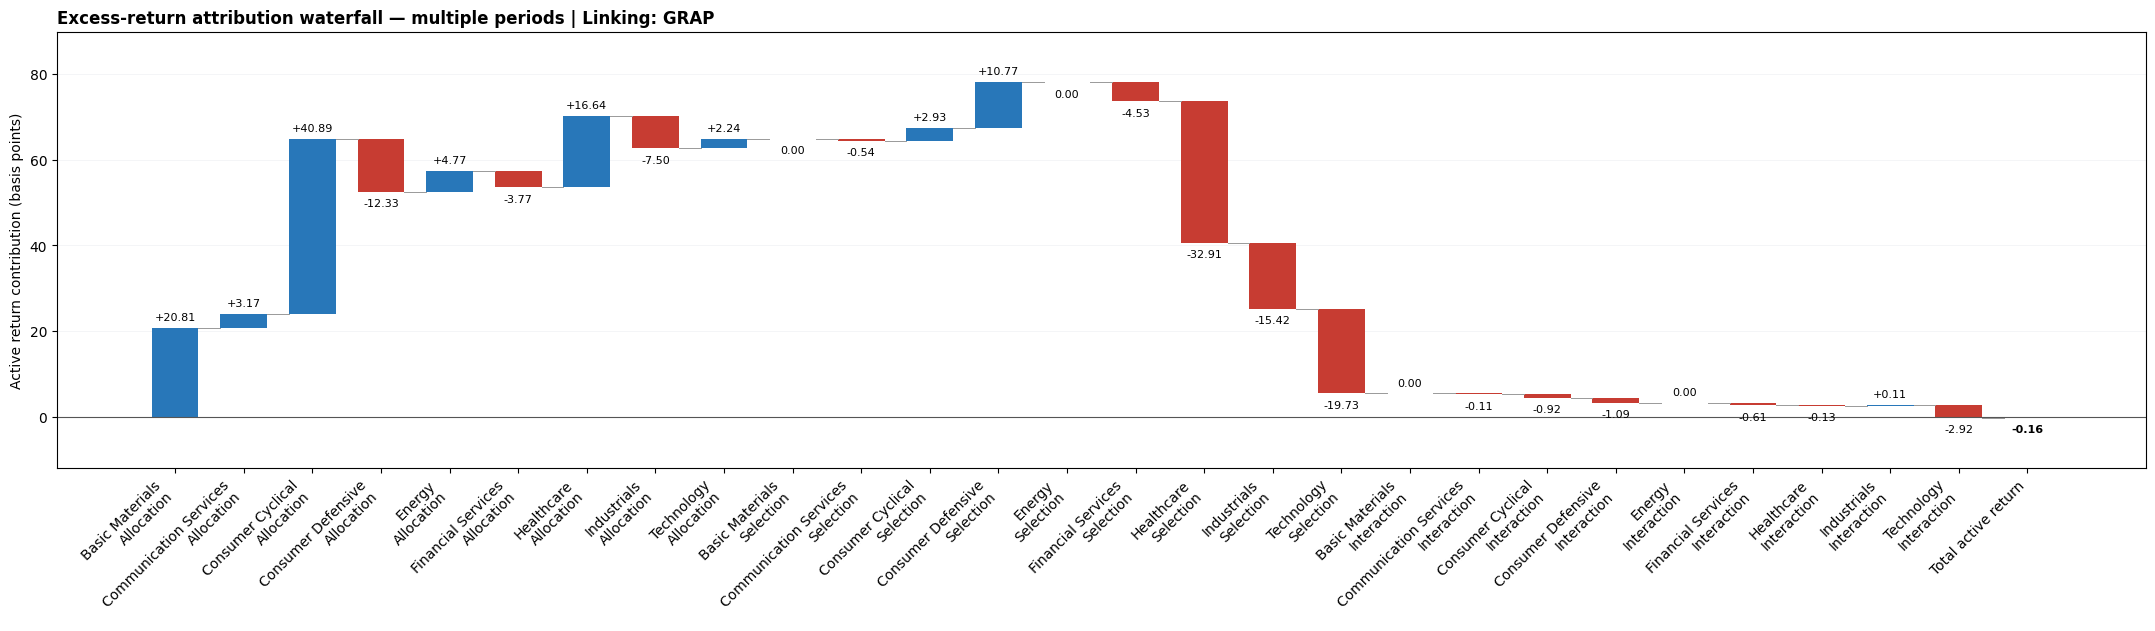

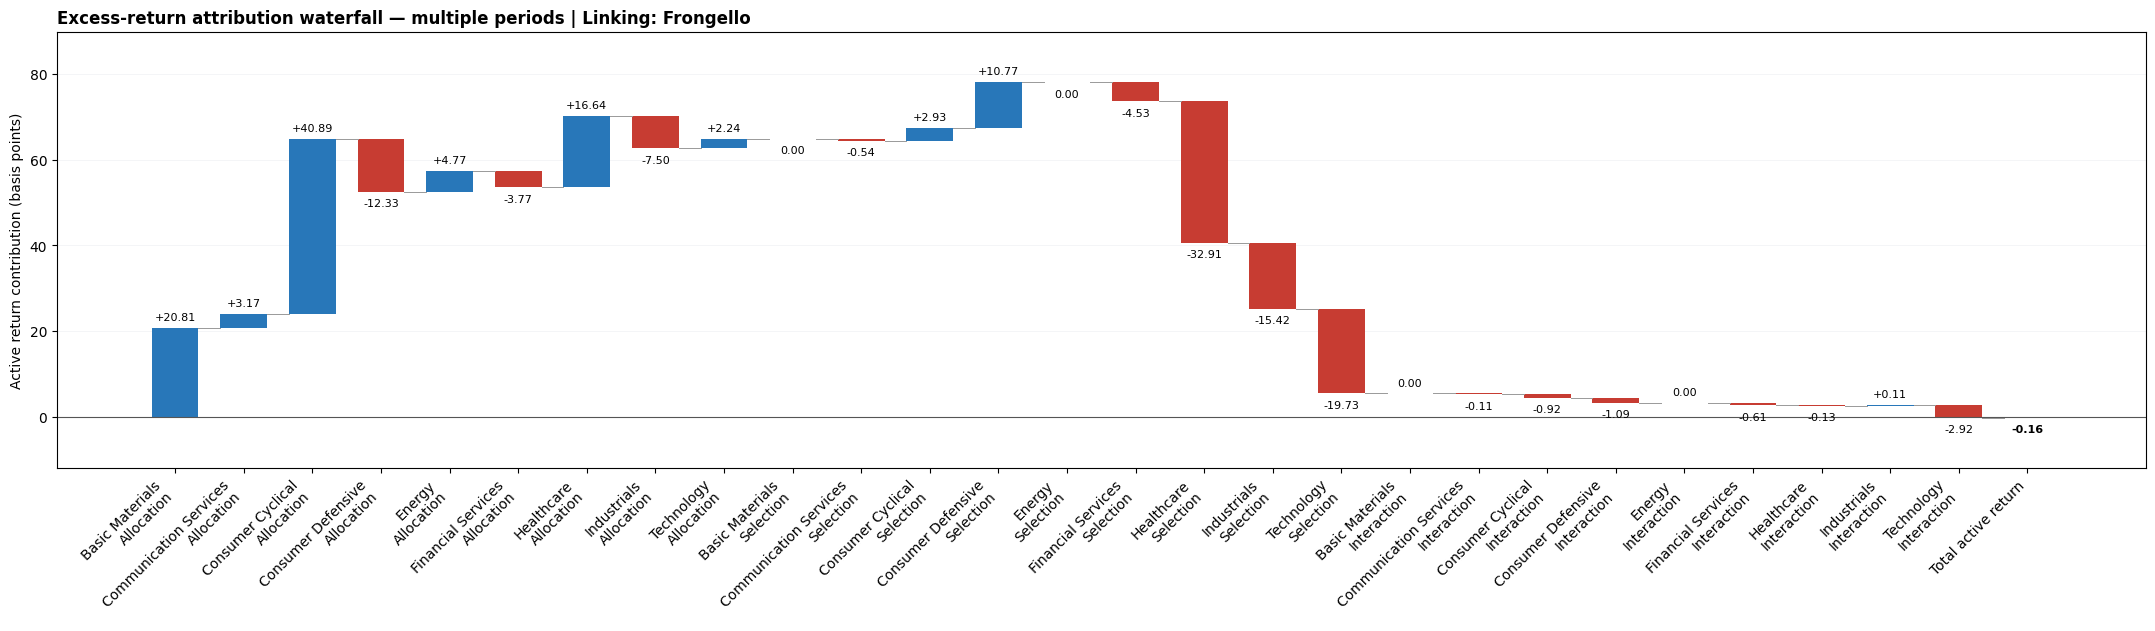

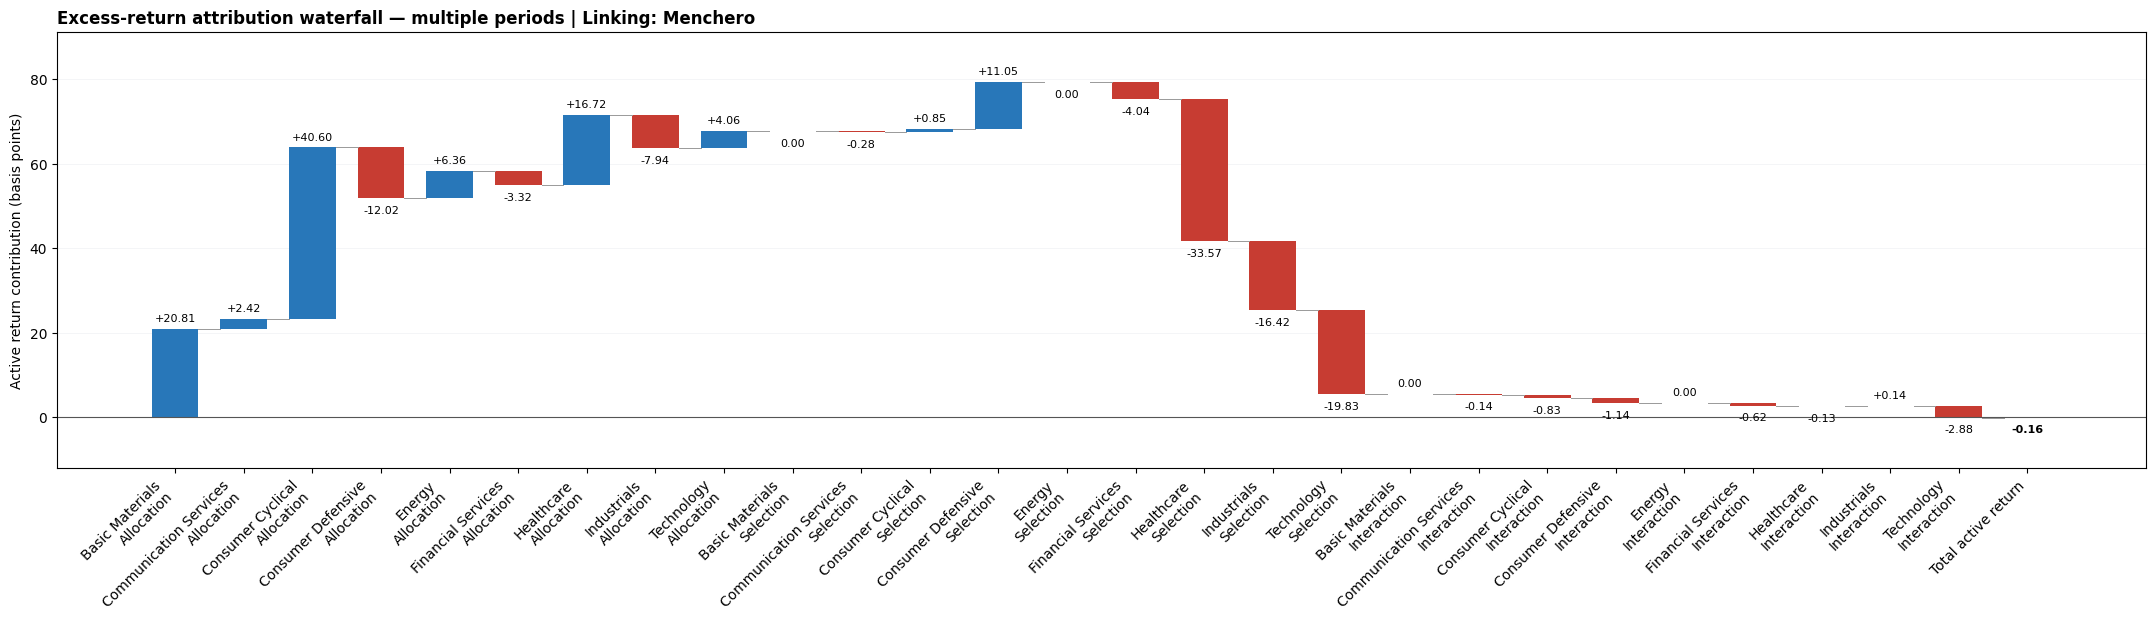

In [16]:
for linker_name, linker_fn in linkers:
    if linker_fn is link_geometric:
        continue  # geometric linking has no category-level linked effects
    fig, ax = chart_multiple_period_excess_return_waterfall(
        result, by_category=True, linking=linker_fn)
    plt.show()


## 14. Aggregate waterfalls for all five linkers

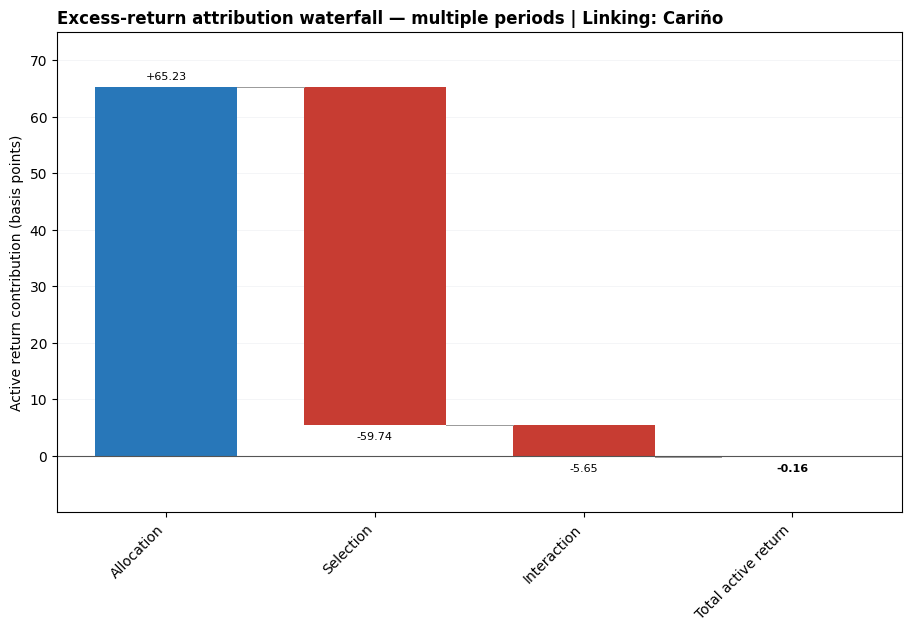

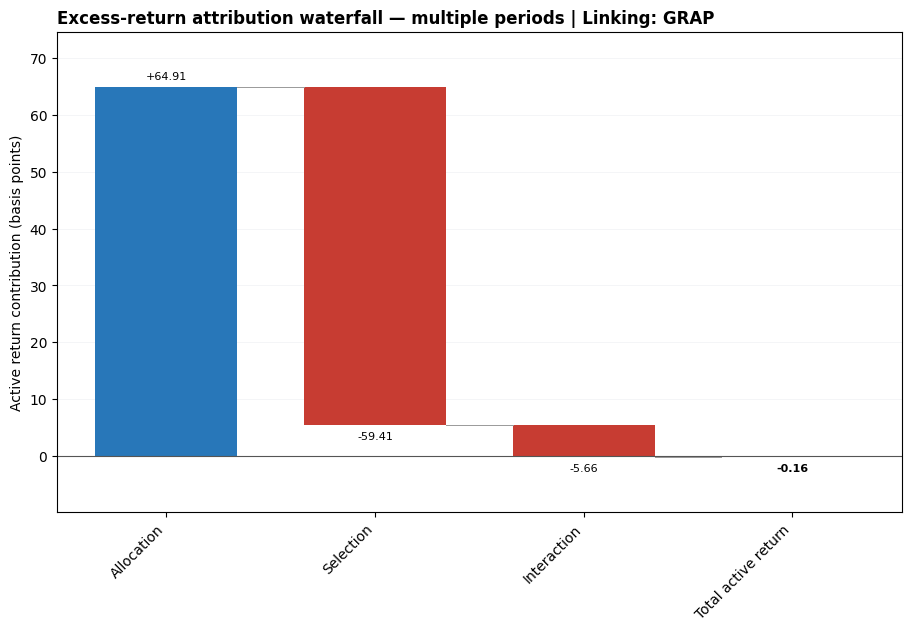

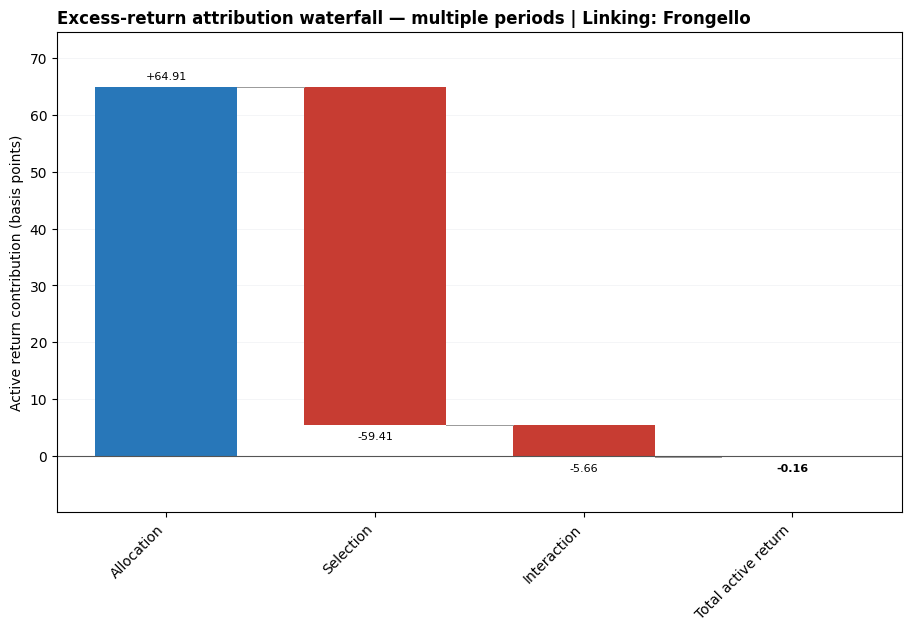

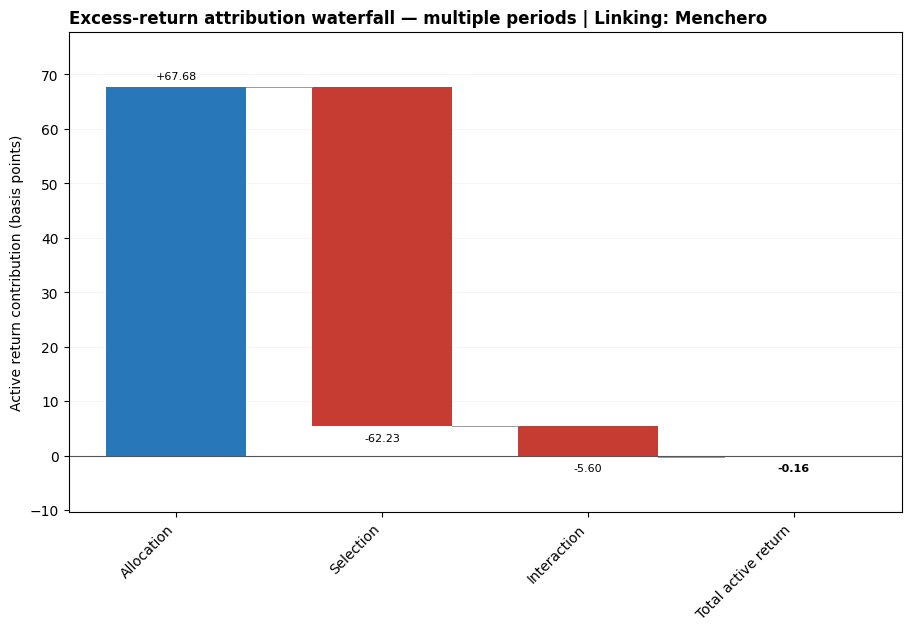

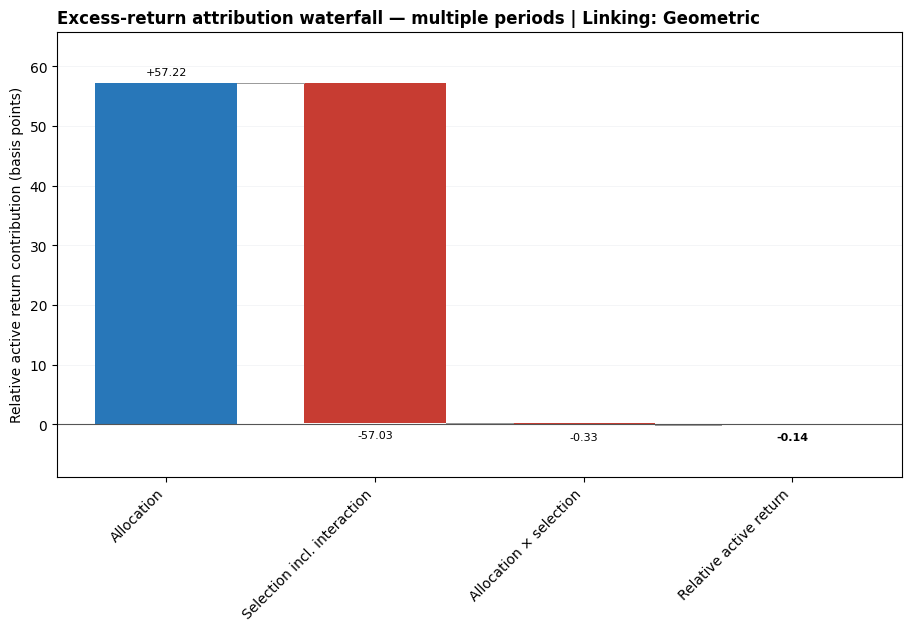

In [17]:
for linker_name, linker_fn in linkers:
    fig, ax = chart_multiple_period_excess_return_waterfall(
        result, by_category=False, linking=linker_fn)
    plt.show()


Category-level linked effects are defined for the four arithmetic methods. The geometric waterfall uses aggregate allocation, selection, the cross term, and relative active return. Different linkers can redistribute effects while preserving their own target identity.